# 2 - Overall and Progression-Free Survival

**Purpose**: Kaplan-Meier survival curves stratified by CIDER T-cell Score
High/Low, for both OS and PFS.

| | |
|---|---|
| **Inputs** | `CIDER_PROJ_DIR/cpi_ready.rds` |
| **Outputs** | `figs/main_survival_figure.png`, `main_pfs_figure.png`, `supporting_survival_*.png` |

All cohort facets (`cohort_broad_go`) split the residual "Other" bucket into **Non-CRC MSI** and **Other MSS** (by `msi_high`) right after load -- see `helpers/shortcuts.r::split_other_by_msi()`. This is display-only, local to this notebook's copy of `ready`; the canonical `cohort_broad`/`cohort_broad_go` in `cpi_ready.rds` are untouched.

In [1]:
source(paste0(dirname(getwd()), "/helpers/map.r"))
source(paste0(dirname(getwd()), "/helpers/shortcuts.r"))
source(paste0(dirname(getwd()), "/helpers/config.r"))
source(paste0(dirname(getwd()), "/helpers/themes.r"))

# Ensure figures output directory exists
dir.create(paste0(CIDER_PROJ_DIR, "figs/"), showWarnings = FALSE, recursive = TRUE)

In [2]:
library(survival)
library(survminer)
library(patchwork)


Attaching package: ‘survminer’




The following object is masked from ‘package:survival’:

    myeloma




# 0 - Read data

In [ ]:
ready <- readRDS(paste0(CIDER_PROJ_DIR, "cpi_ready.rds"))

# Split cohort_broad's residual "Other" bucket into Non-CRC MSI / Other
# (MSS) for every cohort-faceted figure in this notebook -- "Other"
# otherwise mixes MSI-high and microsatellite-stable patients from many
# different tumor types together (see helpers/shortcuts.r::
# split_other_by_msi(), same split already used in Table 1). Level order
# is BROAD_LEVELS_OTHER_SPLIT (helpers/config.r): ICI-Treated / SKCM /
# NSCLC / BLCA / Other MSS / Non-CRC MSI / CRC-MSI -- grouping the two
# MSI-related cohorts together at the end, with Non-CRC MSI placed before
# CRC-MSI, per direction, rather than just appending both Other splits
# after CRC-MSI. Any patient with unresolved
# MSI status falls into "Other (Unknown MSI)", appended at the very end
# only if present, so none silently drop out. cohort_broad_go is rebuilt
# to match -- this mirrors 0_prepare/4_base.ipynb's own cohort_broad_go
# construction exactly, just applied locally to this notebook's copy of
# `ready` rather than the canonical cpi_ready.rds (so every other notebook
# that reads cpi_ready.rds is unaffected by this display-only relabeling).
cohort_other_split_levels <- c(
  BROAD_LEVELS_OTHER_SPLIT,
  intersect("Other (Unknown MSI)", unique(split_other_by_msi(ready$cohort_broad, ready$msi_high)))
)
ready <- ready |>
  mutate(cohort_broad = factor(
    split_other_by_msi(cohort_broad, msi_high),
    levels = cohort_other_split_levels
  )) |>
  group_by(cohort_broad) |>
  mutate(n_broad = n_distinct(sampleId)) |>
  ungroup() |>
  mutate(
    cohort_broad_go = {
      lkp <- distinct(pick(cohort_broad, n_broad)) |> arrange(cohort_broad)
      factor(
        paste0(cohort_broad, " (N = ", n_broad, ")"),
        levels = paste0(lkp$cohort_broad, " (N = ", lkp$n_broad, ")")
      )
    }
  ) |>
  select(-n_broad)

# 1 - Figure function

In [ ]:
# Kaplan-Meier survival plots stratified by CIDER High/Low (median split),
# faceted by cohort. Annotation shows HR and log-rank p-value.
#
# Parameters:
#   data       — cpi_ready
#   cdr3_gp    — T-cell group: "T-cell" or a per-locus group like
#                "T-cell (TRA/TRD)"
#   cohort_col — cohort column to facet on (e.g. "cohort_broad_go")
#   ncols      — columns in patchwork layout
#   title      — overall plot title
#   legend_in_empty_cell — when the panel count doesn't evenly fill the
#     patchwork grid (e.g. 7 panels at ncols = 4 leaves the last cell of the
#     bottom row blank), drop the shared legend into that empty cell instead
#     of placing it beside the whole figure. No effect when there's no
#     empty cell (panel count is a multiple of ncols).
survival_plot <- function(data, cdr3_gp, cohort_col,
                          time_col  = "osDays",
                          event_col = "osEvent",
                          ncols = 3, title = "",
                          legend_in_empty_cell = FALSE) {

  df <- data |>
    filter(gp == cdr3_gp) |>
    rename(cohort_label = all_of(cohort_col))

  panel_order <- levels(droplevels(df$cohort_label))

  nested <- df |>
    group_by(cohort_label) |>
    nest()

  panels <- map2(nested$cohort_label, nested$data, function(label, d) {
    d$surv_time  <- d[[time_col]] / 30.44   # convert days → months
    d$surv_event <- d[[event_col]]

    fit <- survfit(Surv(surv_time, surv_event) ~ group, data = d)
    clean_labels <- gsub("group=", "", names(fit$strata))

    cox     <- coxph(Surv(surv_time, surv_event) ~ group, data = d)
    hr      <- round(exp(coef(cox)), 2)
    p_val   <- summary(cox)$logtest[3]
    p_label <- fmt_pval(p_val)

    # Median survival per CIDER group (Low/High) -- same survminer::surv_median()
    # convention as 3_survival_with_tmb.ipynb's pan_cancer_survival_tmb (Figure
    # 5C). "NR" (not reached) when a stratum's KM curve never crosses 0.5
    # survival, rather than a broken numeric value. endpoint_label keeps this
    # generic across this shared function's two callers: "OS" for Figure 4
    # (event_col = "osEvent"), "PFS" for the PFS supplement (figure_s2.png).
    endpoint_label <- if (event_col == "osEvent") "OS" else if (event_col == "pfsEvent") "PFS" else "Survival"
    med_surv <- survminer::surv_median(fit) |>
      mutate(group_clean = gsub("group=", "", strata))
    med_label <- function(grp) {
      row <- med_surv |> filter(group_clean == grp)
      if (nrow(row) == 0) return(NULL)
      if (is.na(row$median)) paste0(grp, ": NR") else sprintf("%s: %.1f mo", grp, row$median)
    }
    median_lines <- paste(
      c(paste0("Median ", endpoint_label, ":"), med_label("Low"), med_label("High")),
      collapse = "\n"
    )

    annot <- paste0("HR: ", hr, "\n", p_label, "\n", median_lines)

    ggsurvplot(
      fit, data = d,
      legend.labs = clean_labels,
      pval        = annot,
      pval.coord  = c(max(d$surv_time, na.rm = TRUE) * 0.55, 0.85),
      pval.size   = 2.5,
      title       = as.character(label)
    )$plot +
      go_theme +
      theme(plot.title = element_text(hjust = 0.5)) +
      scale_color_manual(values = high_low_color) +
      # reverse = TRUE: cpi_ready's shared `group` factor (0_prepare/4_base.ipynb)
      # is levels = c("Low", "High"), which ggplot would otherwise list Low
      # above High in a vertical legend. Reversed here only -- scoped to this
      # one shared helper (Figure 4 and its PFS supplement, figure_s2.png) --
      # rather than changing the global factor level order, which other
      # figures across the pipeline also rely on.
      guides(color = guide_legend(ncol = 1, reverse = TRUE)) +
      labs(color = "CIDER T-cell Score", x = "Time (months)")
  })
  plot_list     <- setNames(panels, as.character(nested$cohort_label))
  ordered_panels <- plot_list[panel_order]

  if (!legend_in_empty_cell) {
    return(
      patchwork::wrap_plots(ordered_panels, ncol = ncols, guides = "collect") +
        figure_annotation(title, tag = FALSE, legend_pos = "right")
    )
  }

  # n_empty: how many trailing grid cells are left blank once the panels
  # fill the grid row-major (left to right, top to bottom) -- 0 when the
  # panel count is already a multiple of ncols, in which case this behaves
  # exactly like the branch above (collected legend placed beside the grid,
  # since there's no empty cell to use instead).
  n_empty <- (ncols - length(ordered_panels) %% ncols) %% ncols
  if (n_empty == 0) {
    return(
      patchwork::wrap_plots(ordered_panels, ncol = ncols, guides = "collect") +
        figure_annotation(title, tag = FALSE, legend_pos = "right")
    )
  }

  # Pull one shared legend from the first panel (every panel's legend is
  # identical -- same high_low_color mapping) before stripping legends from
  # every real panel. Any cells left empty before the final one (only
  # possible if n_empty > 1) get a blank spacer so the legend lands
  # specifically in the LAST -- i.e. bottom-right-most -- empty cell.
  # Slightly larger than go_theme's default legend text/title/key size --
  # this legend fills a whole grid cell on its own (same size as every real
  # panel), so go_theme's normal size reads as too small/empty next to the
  # panels around it. Only affects the extracted legend grob below, not
  # ordered_panels[[1]] itself (ggplot's `+` returns a new object).
  shared_legend  <- ggpubr::get_legend(
    ordered_panels[[1]] +
      theme(
        legend.title    = element_text(size = 12, face = "bold", colour = COL_INK),
        legend.text     = element_text(size = 11, colour = COL_INK),
        legend.key.size = unit(1.4, "lines")
      )
  )
  ordered_panels <- lapply(ordered_panels, function(p) p + theme(legend.position = "none"))
  for (i in seq_len(n_empty - 1)) ordered_panels[[length(ordered_panels) + 1]] <- patchwork::plot_spacer()
  ordered_panels[[length(ordered_panels) + 1]] <- patchwork::wrap_elements(shared_legend)

  patchwork::wrap_plots(ordered_panels, ncol = ncols) +
    figure_annotation(title, tag = FALSE)
}

# 2 - Main figure: overall T-cell survival

In [ ]:
main_survival_figure <- survival_plot(
  ready, "T-cell", "cohort_broad_go", ncols = 4,
  title = "Overall Survival vs CIDER T-cell Score",
  # 7 cohort panels at ncols = 4 leaves the last cell of row 2 (bottom-right)
  # empty -- drop the shared legend there instead of beside the figure.
  legend_in_empty_cell = TRUE
)
set_plot_dims(12, 9); main_survival_figure
saveRDS(main_survival_figure, paste0(CIDER_PROJ_DIR, "figs/main_survival_figure.rds"))

# 3 - Supporting: T-cell survival

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


...

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


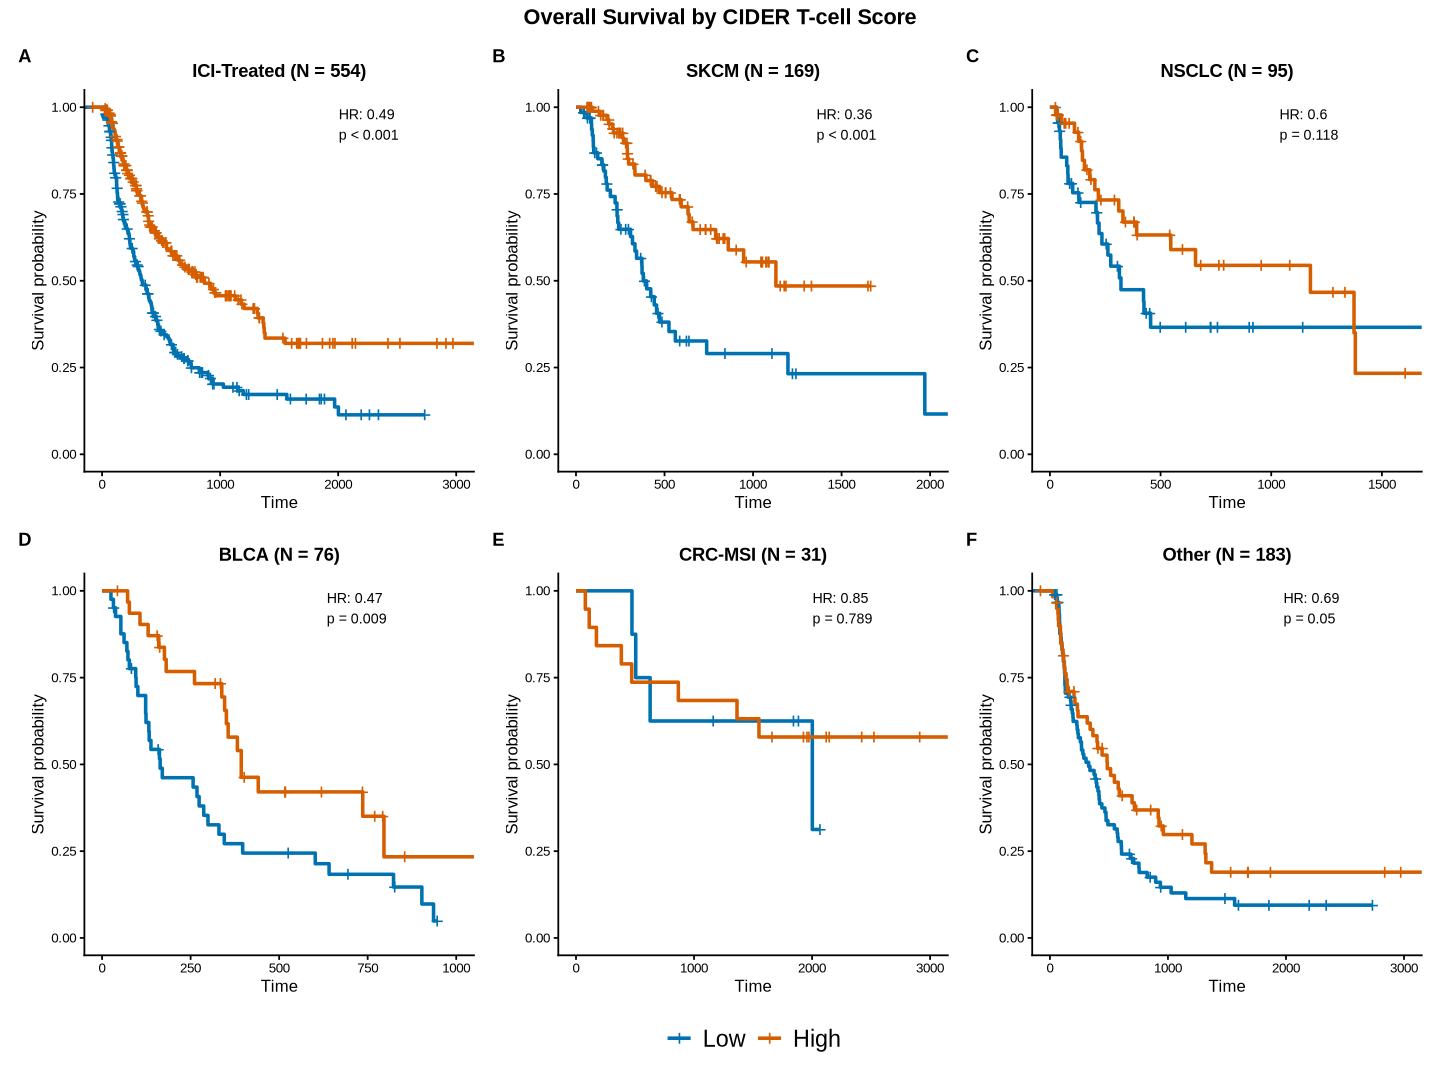

In [7]:
supporting_survival_tcell <- survival_plot(
  ready, "T-cell", "cohort_broad_go", ncols = 3,
  title = "Overall Survival by CIDER T-cell Score"
)
saveRDS(supporting_survival_tcell, paste0(CIDER_PROJ_DIR, "figs/supporting_survival_tcell.rds"))
set_plot_dims(12, 9); supporting_survival_tcell

# 4 - PFS: overall T-cell infiltration

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


...

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


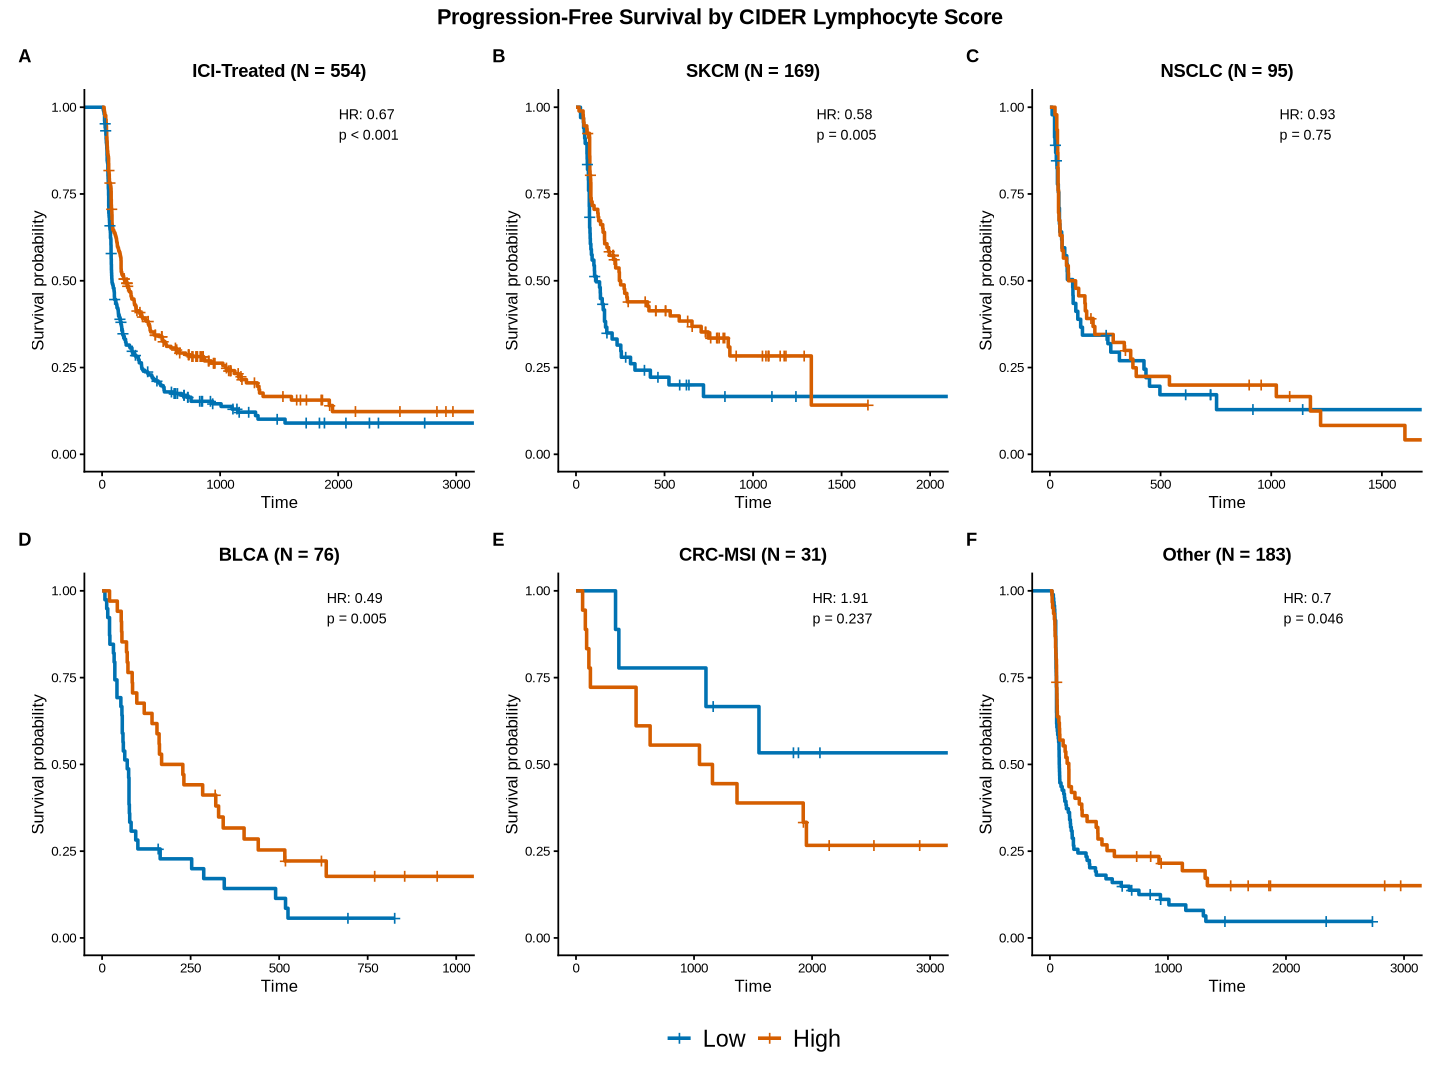

In [9]:
main_pfs_figure <- survival_plot(
  ready, "T-cell", "cohort_broad_go",
  time_col  = "pfsEventDays",
  event_col = "pfsEvent",
  ncols = 3,
  title = "Progression-Free Survival by CIDER T-cell Score"
)
saveRDS(main_pfs_figure, paste0(CIDER_PROJ_DIR, "figs/main_pfs_figure.rds"))
set_plot_dims(12, 9); main_pfs_figure

# 5 - PFS supporting: T-cell

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


...

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


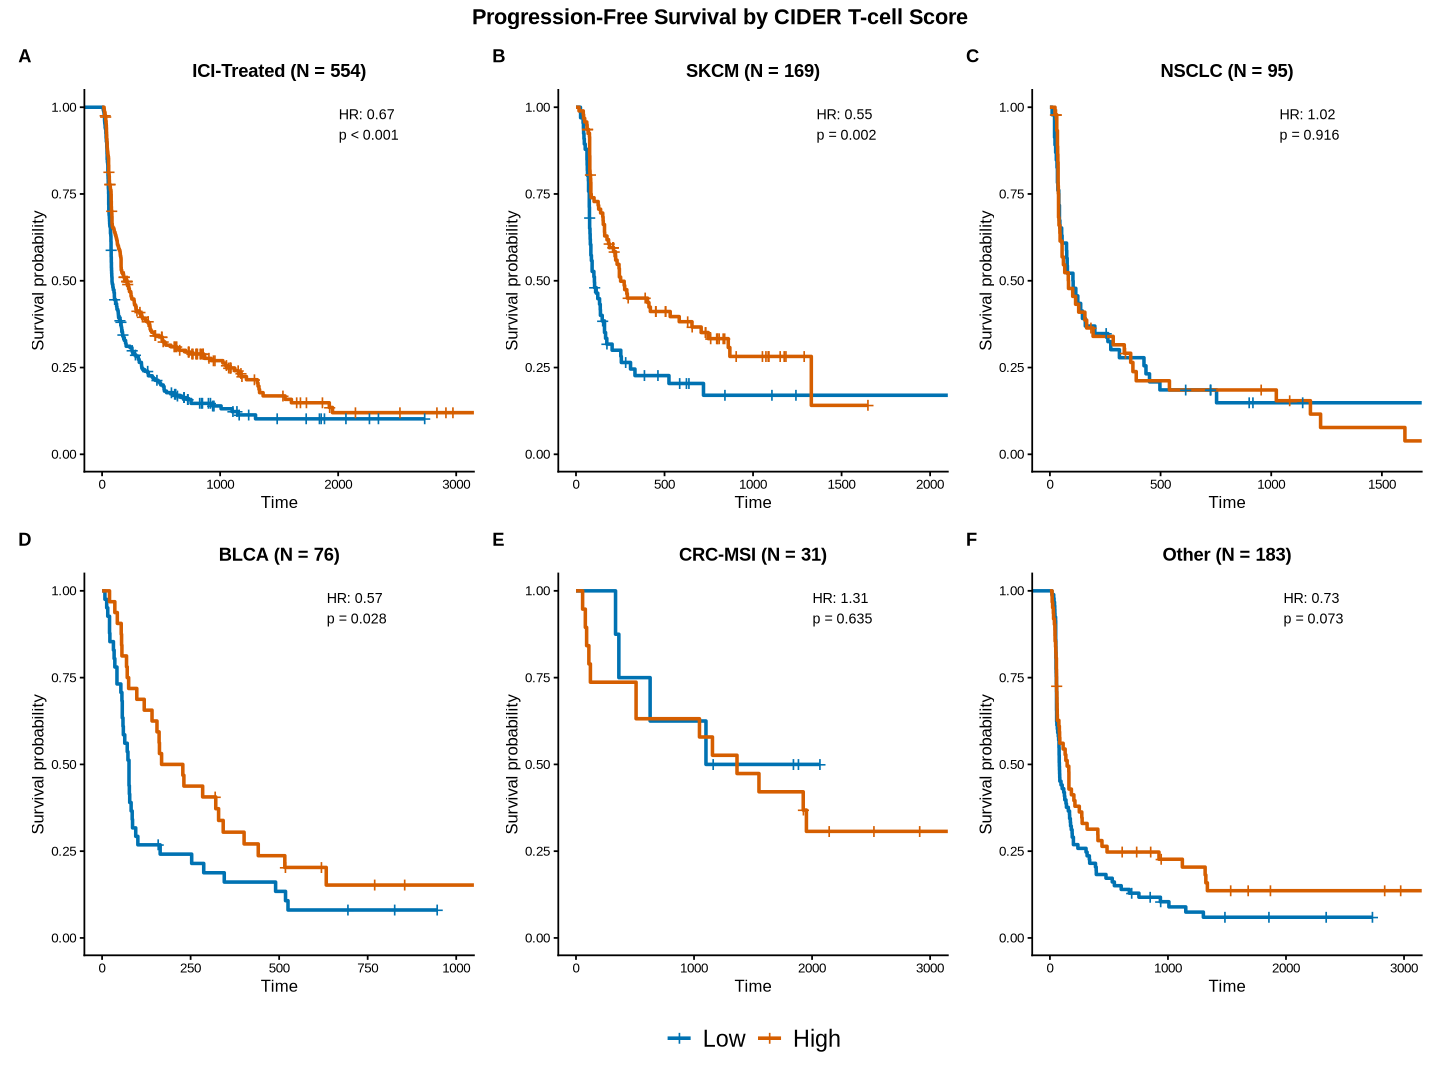

In [10]:
supporting_pfs_tcell <- survival_plot(
  ready, "T-cell", "cohort_broad_go",
  time_col  = "pfsEventDays",
  event_col = "pfsEvent",
  ncols = 3,
  title = "Progression-Free Survival by CIDER T-cell Score"
)
set_plot_dims(12, 9); supporting_pfs_tcell